In [1]:
import os
import re
import sys

sys.path.append("../")

import analysis
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.signal import periodogram

base_path = r"C:\Users\sl57562\The University of Texas at Austin\Acoustic + Calcium - Documents\Acoustic\paper data 3\20261019"

In [17]:
def analysis_periodogram(base_path, mask_size, test_type, band_half_width_hz=1e3, center_frequency_hz=None):
    # For 0.70 mm, the two test types are equivalent, so redirect the normalized series
    # to the unnormalized dataset before loading the folders.
    if mask_size == "0.70mm" and test_type == "1mW_Pout":
        test_type = "53mW_Pin"

    folder_prefix = f"{mask_size}Mask_{test_type}_"

    voltage_scans = []
    for folder in os.listdir(base_path):
        if not os.path.isdir(os.path.join(base_path, folder)):
            continue

        match = re.fullmatch(
            rf"{re.escape(mask_size)}Mask_{re.escape(test_type)}_(\d+(?:\.\d+)?)V",
            folder,
        )
        if match is None:
            continue

        voltage_scans.append((float(match.group(1)), folder))

    voltage_scans.sort(key=lambda item: item[0])
    signal_scans = [(voltage_value, folder) for voltage_value, folder in voltage_scans if voltage_value != 0]

    if not signal_scans:
        raise ValueError(f"No signal folders found for mask_size={mask_size} and test_type={test_type}")

    noise_folder = next((folder for voltage_value, folder in voltage_scans if voltage_value == 0), None)
    if noise_folder is None:
        raise ValueError(f"No noise folder found for mask_size={mask_size} and test_type={test_type}")

    print(f"Analyzing {folder_prefix}: found {len(signal_scans)} signal scans and 1 noise reference")

    rows = max(1, int(np.ceil(len(signal_scans) / 3)))
    cols = 3
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows), squeeze=False)
    axes = axes.flatten()

    results = {}

    for ax, (voltage_value, voltage_folder) in zip(axes, signal_scans):
        signal_path = os.path.join(base_path, voltage_folder)
        noise_path = os.path.join(base_path, noise_folder)

        signal_files = [
            os.path.join(signal_path, f"iter_{x}.tdms")
            for x in range(10)
            if os.path.exists(os.path.join(signal_path, f"iter_{x}.tdms"))
        ]
        noise_files = [
            os.path.join(noise_path, f"iter_{x}.tdms")
            for x in range(10)
            if os.path.exists(os.path.join(noise_path, f"iter_{x}.tdms"))
        ]

        if not signal_files or not noise_files:
            print(f"Skipping {voltage_folder}: missing signal or noise files")
            continue

        print(f"  Processing {voltage_folder} with {len(signal_files)} signal files and {len(noise_files)} noise files")

        system = analysis.System(
            f"{folder_prefix}{voltage_value}V",
            signal_files + noise_files,
            channel="X",
            set_data=True,
        )

        freqs = None
        signal_psds = []
        noise_psds = []

        for dataset_idx, dataset in enumerate(system.get_data()):
            dataset.apply("detrend", mode="linear", inplace=True)
            group = "signal" if dataset_idx < len(signal_files) else "noise"

            for collection in dataset.collection:
                sample_rate = getattr(dataset, "r", None)
                if freqs is None:
                    freqs, psd = welch(collection.x, sample_rate, nfft=2**15, nperseg=2**14)
                    #freqs, psd = periodogram(collection.x, sample_rate, nfft=2**15)
                else:
                    _, psd = welch(collection.x, sample_rate, nfft=2**15, nperseg=2**14)
                    #_, psd = periodogram(collection.x, sample_rate, nfft=2**15)
                
                if group == "signal":
                    signal_psds.append(psd)
                else:
                    noise_psds.append(psd)
                
        avg_freqs = freqs
        avg_signal_psd = np.mean(np.asarray(signal_psds), axis=0)
        avg_noise_psd = np.mean(np.asarray(noise_psds), axis=0)

        band_min_idx = np.searchsorted(avg_freqs, center_frequency_hz - band_half_width_hz)
        band_max_idx = np.searchsorted(avg_freqs, center_frequency_hz + band_half_width_hz)
        # print(
        #     f"    In-band bounds (Hz): {avg_freqs[band_min_idx]:.0f} to {avg_freqs[max(band_max_idx - 1, band_min_idx)]:.0f}"
        # )

        wideband_signal_power = np.trapezoid(avg_signal_psd, avg_freqs)
        wideband_noise_power = np.trapezoid(avg_noise_psd, avg_freqs)
        snr_wideband = 20 * np.log10(wideband_signal_power / wideband_noise_power)

        #SNR by integration under curve
        inband_signal_power = np.trapezoid(
            avg_signal_psd[band_min_idx:band_max_idx],
            avg_freqs[band_min_idx:band_max_idx],
        )
        inband_noise_power = np.trapezoid(
            avg_noise_psd[band_min_idx:band_max_idx],
            avg_freqs[band_min_idx:band_max_idx],
        )
        snr_inband = 20 * np.log10(inband_signal_power / inband_noise_power)

        # #SNR by maximum
        # #how wide of a range it scans is determined by the band_half_width_hz variable in def
        # band_slice = avg_signal_psd[band_min_idx:band_max_idx]
        # local_inband_index = np.argmax(band_slice)
        # inband_signal_index = band_min_idx + local_inband_index
        # # print(inband_signal_index)
        # inband_signal = avg_signal_psd[inband_signal_index]
        # print("Signal value:")
        # print(inband_signal)
        # inband_noise = avg_noise_psd[inband_signal_index]
        # #print(inband_noise)
        # snr_inband = 20 * np.log10(inband_signal / inband_noise)


        results[voltage_value] = {
            "freqs": avg_freqs,
            "signal": avg_signal_psd,
            "noise": avg_noise_psd,
            "snr_wideband": snr_wideband,
            "snr_inband": snr_inband,
            "band_min_idx": band_min_idx,
            "band_max_idx": band_max_idx,
        }
        def calculate_NEP(snr_inband, voltage_value):
            stroke_distance = [0.05, 0.09, 0.14, 0.19, 0.24, 0.30, 0.35, 0.40, 0.46, 0.44] #stroke distance in nm
            rho = 1.2041 #kg/m^3 at 21 degrees C, desnity of air
            c = 343.21 #m/2 @ 21 degrees C, speed of sound in air
            f = center_frequency_hz
            omega = 2*np.pi*f
            X_o = stroke_distance[int(voltage_value-1)] * 1e-9
            P = rho*c*omega*X_o
            if snr_inband < 1.0:
                NEP = "Null"
            else:
                NEP = P / snr_inband 
                NEP = round(NEP, 4)
            return NEP


        ax.loglog(avg_freqs, avg_signal_psd, label="Signal", alpha=0.7)
        ax.loglog(avg_freqs, avg_noise_psd, label="Noise", alpha=0.7)
        # ax.axvline(avg_freqs[band_min_idx], color="k", linestyle="--", linewidth=0.5)
        # ax.axvline(avg_freqs[max(band_max_idx - 1, band_min_idx)], color="k", linestyle="--", linewidth=0.5)
        ax.set_title(f"{voltage_value} V\nIn-band SNR: {snr_inband:.1f} dB\nNEP: {calculate_NEP(snr_inband, voltage_value)} Pa")
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("PSD")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=7)
        ax.set_ylim(1e-16, 1e-6)

        print(f"    In-band SNR: {snr_inband:.2f} dB | Wideband SNR: {snr_wideband:.2f} dB")
        print(f"    NEP: {calculate_NEP(snr_inband, voltage_value)} Pa")

    for ax in axes[len(results):]:
        ax.set_visible(False)

    fig.suptitle(f"{mask_size} Mask PSDs and SNRs")
    fig.tight_layout()
    #plt.show()

# plots snr vs voltage    
    # voltage_values = sorted(results.keys())
    # snr_values = [results[voltage]["snr_inband"] for voltage in voltage_values]

    # fig2, ax2 = plt.subplots(figsize=(6, 4))
    # ax2.plot(voltage_values, snr_values, "o-", color="tab:blue")
    # ax2.set_xlabel("Voltage (V)")
    # ax2.set_ylabel("In-band SNR (dB)")
    # ax2.set_title(f"{power_mw} mW: SNR vs voltage")
    # ax2.grid(True, alpha=0.3)
    # fig2.tight_layout()
    # plt.show()

    return results




Analyzing noMask_53mW_Pin_: found 20 signal scans and 1 noise reference
  Processing noMask_53mW_Pin_0.5V with 10 signal files and 10 noise files
    In-band SNR: 0.05 dB | Wideband SNR: -1.91 dB
    NEP: Null Pa
  Processing noMask_53mW_Pin_1V with 10 signal files and 10 noise files
    In-band SNR: 0.25 dB | Wideband SNR: -1.14 dB
    NEP: Null Pa
  Processing noMask_53mW_Pin_1.5V with 10 signal files and 10 noise files
    In-band SNR: 0.59 dB | Wideband SNR: -0.74 dB
    NEP: Null Pa
  Processing noMask_53mW_Pin_2V with 10 signal files and 10 noise files
    In-band SNR: 1.04 dB | Wideband SNR: -1.06 dB
    NEP: 0.0245 Pa
  Processing noMask_53mW_Pin_2.5V with 10 signal files and 10 noise files
    In-band SNR: 1.57 dB | Wideband SNR: -1.14 dB
    NEP: 0.0163 Pa
  Processing noMask_53mW_Pin_3V with 10 signal files and 10 noise files
    In-band SNR: 1.99 dB | Wideband SNR: -0.79 dB
    NEP: 0.0199 Pa
  Processing noMask_53mW_Pin_3.5V with 10 signal files and 10 noise files
    In-b

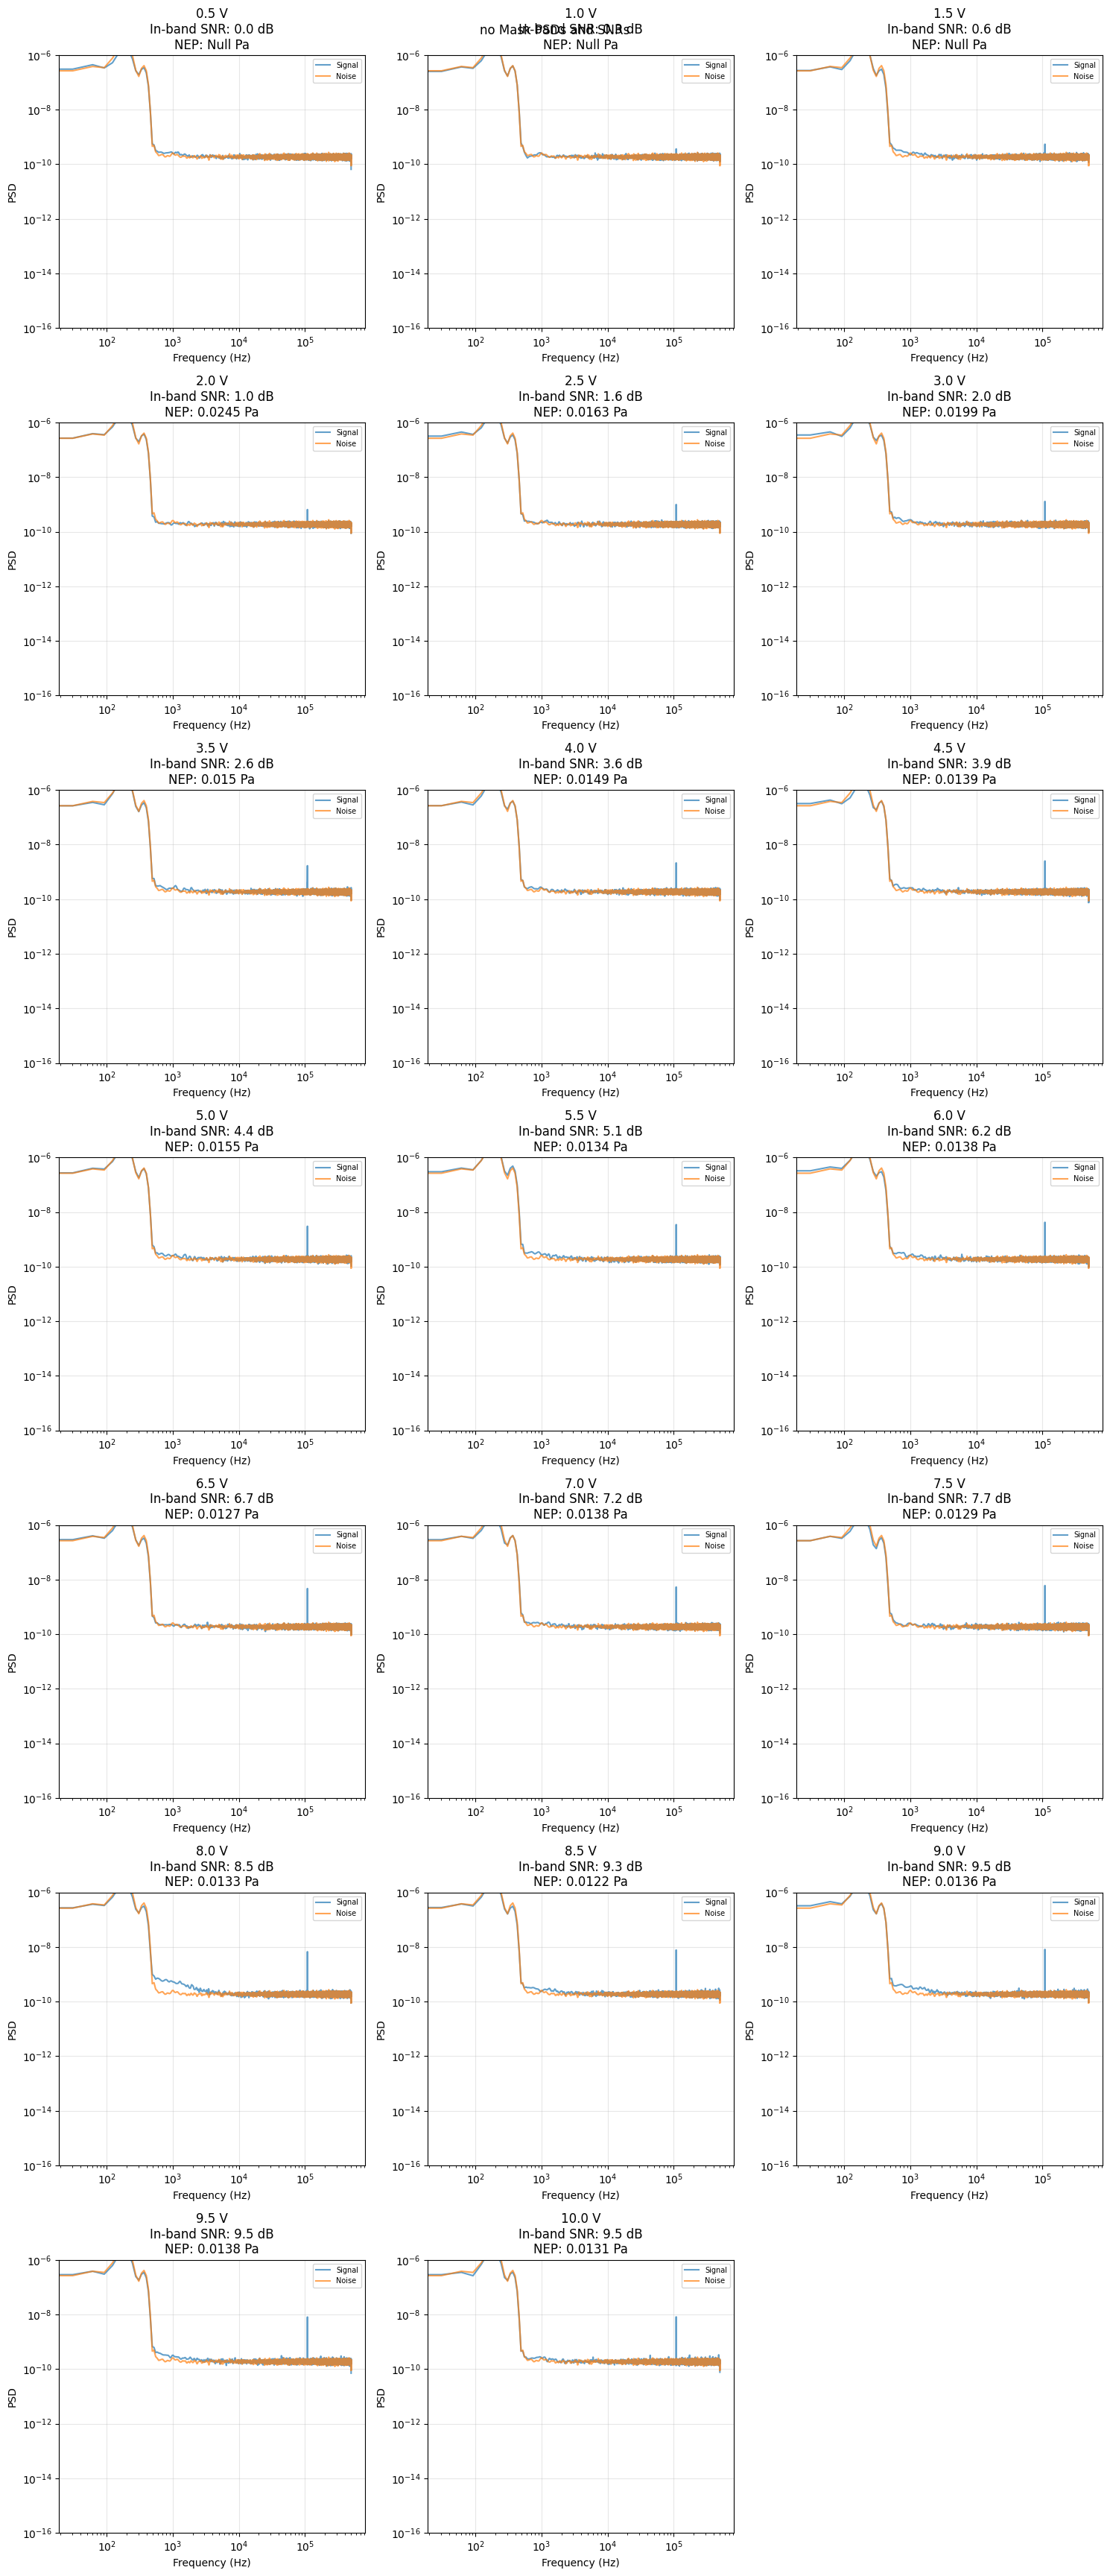

In [14]:
normalized = "1mW_Pout"
unnormalized = "53mW_Pin"
results = analysis_periodogram(base_path, mask_size='no', test_type=unnormalized, band_half_width_hz=1e3, center_frequency_hz=109000)

In [ ]:
def analysis_welches(power_mw, base_path, band_half_width_hz=1e3):
    power_pattern = f"pof_{power_mw}mW"
    noise_folder = f"{power_pattern}_noise"

    voltage_scans = [
        (float(re.search(r"_(\d+(?:\.\d+)?)V$", folder).group(1)), folder)
        for folder in os.listdir(base_path)
        if os.path.isdir(os.path.join(base_path, folder))
        and folder.startswith(f"{power_pattern}_")
        and "noise" not in folder
        and re.search(r"_(\d+(?:\.\d+)?)V$", folder)
    ]
    voltage_scans.sort(key=lambda item: item[0], reverse=True)
    voltage_folders = [folder for _, folder in voltage_scans]

    if not voltage_scans:
        raise ValueError(f"No voltage scan folders found for {power_pattern}")

    print(f"Analyzing {power_pattern}: found {len(voltage_scans)} voltage scans")

    rows, cols = 4, 3
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows), squeeze=False)
    axes = axes.flatten()

    results = {}

    for ax, (voltage_value, voltage_folder) in zip(axes, voltage_scans):
        frequency_match = re.search(r"_(\d+(?:\.\d+)?)kHz_", voltage_folder)
        if frequency_match is None:
            continue

        center_frequency_hz = float(frequency_match.group(1)) * 1e3 
        signal_path = os.path.join(base_path, voltage_folder)
        noise_path = os.path.join(base_path, noise_folder)

        signal_files = [
            os.path.join(signal_path, f"iter_{x}.tdms")
            for x in range(5) #drop to 5 to exclude data thats further drifted from alignement
            if os.path.exists(os.path.join(signal_path, f"iter_{x}.tdms"))
        ]
        noise_files = [
            os.path.join(noise_path, f"iter_{x}.tdms")
            for x in range(5) #drop to 5 to exclude data thats further drifted from alignement
            if os.path.exists(os.path.join(noise_path, f"iter_{x}.tdms"))
        ]

        if not signal_files or not noise_files:
            print(f"Skipping {voltage_folder}: missing signal or noise files")
            continue

        print(f"  Processing {voltage_folder} with {len(signal_files)} signal files and {len(noise_files)} noise files")

        system = analysis.System(
            f"{power_pattern}_{voltage_folder}",
            signal_files + noise_files,
            channel="X",
            set_data=True,
        )

        freqs = None
        signal_psds = []
        noise_psds = []

        for dataset_idx, dataset in enumerate(system.get_data()):
            dataset.apply("detrend", mode="linear", inplace=True)

            group = "signal" if dataset_idx < len(signal_files) else "noise"

            for collection in dataset.collection:
                sample_rate = getattr(dataset, "r", None)
                if freqs is None:
                    freqs, psd = welch(collection.x, sample_rate, nfft=2**15, nperseg=2**14)
                else:
                    _, psd = welch(collection.x, sample_rate, nfft=2**15, nperseg=2**14)

                if group == "signal":
                    signal_psds.append(psd)
                else:
                    noise_psds.append(psd)

        avg_freqs = freqs
        avg_signal_psd = np.mean(np.asarray(signal_psds), axis=0)
        avg_noise_psd = np.mean(np.asarray(noise_psds), axis=0)

        band_min_idx = np.searchsorted(avg_freqs, center_frequency_hz - band_half_width_hz)
        band_max_idx = np.searchsorted(avg_freqs, center_frequency_hz + band_half_width_hz)
        # print(
        #     f"    In-band bounds (Hz): {avg_freqs[band_min_idx]:.0f} to {avg_freqs[max(band_max_idx - 1, band_min_idx)]:.0f}"
        # )

        wideband_signal_power = np.trapezoid(avg_signal_psd, avg_freqs)
        wideband_noise_power = np.trapezoid(avg_noise_psd, avg_freqs)
        snr_wideband = 20 * np.log10(wideband_signal_power / wideband_noise_power)

        # SNR by integration

        inband_signal_power = np.trapezoid(
            avg_signal_psd[band_min_idx:band_max_idx],
            avg_freqs[band_min_idx:band_max_idx],
        )
        inband_noise_power = np.trapezoid(
            avg_noise_psd[band_min_idx:band_max_idx],
            avg_freqs[band_min_idx:band_max_idx],
        )
        snr_inband = 20 * np.log10(inband_signal_power / inband_noise_power)

        #SNR by maximum
        # #how wide of a range it scans is determined by the band_half_width_hz variable in def
        # band_slice = avg_signal_psd[band_min_idx:band_max_idx]
        # local_inband_index = np.argmax(band_slice)
        # inband_signal_index = band_min_idx + local_inband_index
        # #print(inband_signal_index)
        # inband_signal = avg_signal_psd[inband_signal_index]
        # #print(inband_signal)
        # inband_noise = avg_noise_psd[inband_signal_index]
        # #print(inband_noise)
        # snr_inband = 20 * np.log10(inband_signal / inband_noise)

        results[voltage_value] = {
            "freqs": avg_freqs,
            "signal": avg_signal_psd,
            "noise": avg_noise_psd,
            "snr_wideband": snr_wideband,
            "snr_inband": snr_inband,
            "band_min_idx": band_min_idx,
            "band_max_idx": band_max_idx,
        }

        def calculate_NEP(snr_inband, voltage_value):
            stroke_distance = [0.05, 0.09, 0.14, 0.19, 0.24, 0.30, 0.35, 0.40, 0.46, 0.44] #stroke distance in nm
            rho = 1.2041 #kg/m^3 at 21 degrees C, desnity of air
            c = 343.21 #m/2 @ 21 degrees C, speed of sound in air
            f = center_frequency_hz
            omega = 2*np.pi*f
            X_o = stroke_distance[int(voltage_value-1)] * 1e-9
            P = rho*c*omega*X_o
            if snr_inband < 1.0:
                NEP = "Null"
            else:
                NEP = P / snr_inband 
                NEP = round(NEP, 4)
            return NEP

        ax.loglog(avg_freqs, avg_signal_psd, label="Signal", alpha=0.7)
        ax.loglog(avg_freqs, avg_noise_psd, label="Noise", alpha=0.7)
        # ax.axvline(avg_freqs[band_min_idx], color="k", linestyle="--", linewidth=0.5)
        # ax.axvline(avg_freqs[max(band_max_idx - 1, band_min_idx)], color="k", linestyle="--", linewidth=0.5)

        ax.set_title(f"{voltage_value} V\nIn-band SNR: {snr_inband:.1f} dB\nNEP: {calculate_NEP(snr_inband, voltage_value)} Pa")
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("PSD")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=7)
        ax.set_ylim(1e-16, 1e-6)

        print(f"    In-band SNR: {snr_inband:.2f} dB")
        print(f"    NEP: {calculate_NEP(snr_inband, voltage_value)} Pa")

    for ax in axes[len(results):]:
        ax.set_visible(False)

    fig.suptitle(f"{power_mw} mW PSDs and SNRs")
    fig.tight_layout()
    # plt.show()

# plots snr vs voltage
    # voltage_values = sorted(results.keys())
    # snr_values = [results[voltage]["snr_inband"] for voltage in voltage_values]

    # fig2, ax2 = plt.subplots(figsize=(6, 4))
    # ax2.plot(voltage_values, snr_values, "o-", color="tab:blue")
    # ax2.set_xlabel("Voltage (V)")
    # ax2.set_ylabel("In-band SNR (dB)")
    # ax2.set_title(f"{power_mw} mW: SNR vs voltage")
    # ax2.grid(True, alpha=0.3)
    # fig2.tight_layout()
    # plt.show()

    return results

results = analysis_welches(21, base_path)


Analyzing noMask_1mW_Pout_: found 20 signal scans and 1 noise reference
  Processing noMask_1mW_Pout_0.5V with 10 signal files and 10 noise files
    In-band SNR: 0.35 dB | Wideband SNR: 0.06 dB
    NEP: Null Pa
  Processing noMask_1mW_Pout_1V with 10 signal files and 10 noise files
    In-band SNR: -0.33 dB | Wideband SNR: -0.27 dB
    NEP: Null Pa
  Processing noMask_1mW_Pout_1.5V with 10 signal files and 10 noise files
    In-band SNR: 2.32 dB | Wideband SNR: 0.19 dB
    NEP: 0.0061 Pa
  Processing noMask_1mW_Pout_2V with 10 signal files and 10 noise files
    In-band SNR: 2.90 dB | Wideband SNR: -0.15 dB
    NEP: 0.0088 Pa
  Processing noMask_1mW_Pout_2.5V with 10 signal files and 10 noise files
    In-band SNR: 2.85 dB | Wideband SNR: -0.11 dB
    NEP: 0.0089 Pa
  Processing noMask_1mW_Pout_3V with 10 signal files and 10 noise files
    In-band SNR: 4.52 dB | Wideband SNR: -0.37 dB
    NEP: 0.0088 Pa
  Processing noMask_1mW_Pout_3.5V with 10 signal files and 10 noise files
    In-

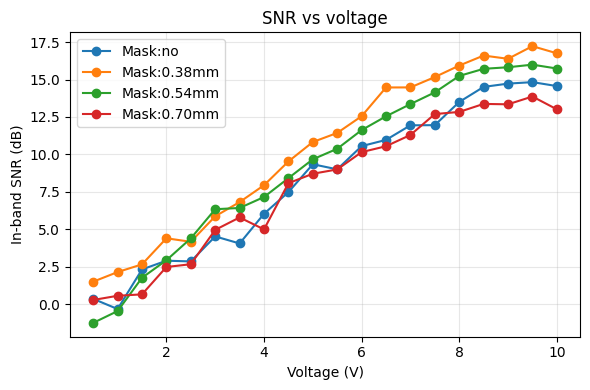

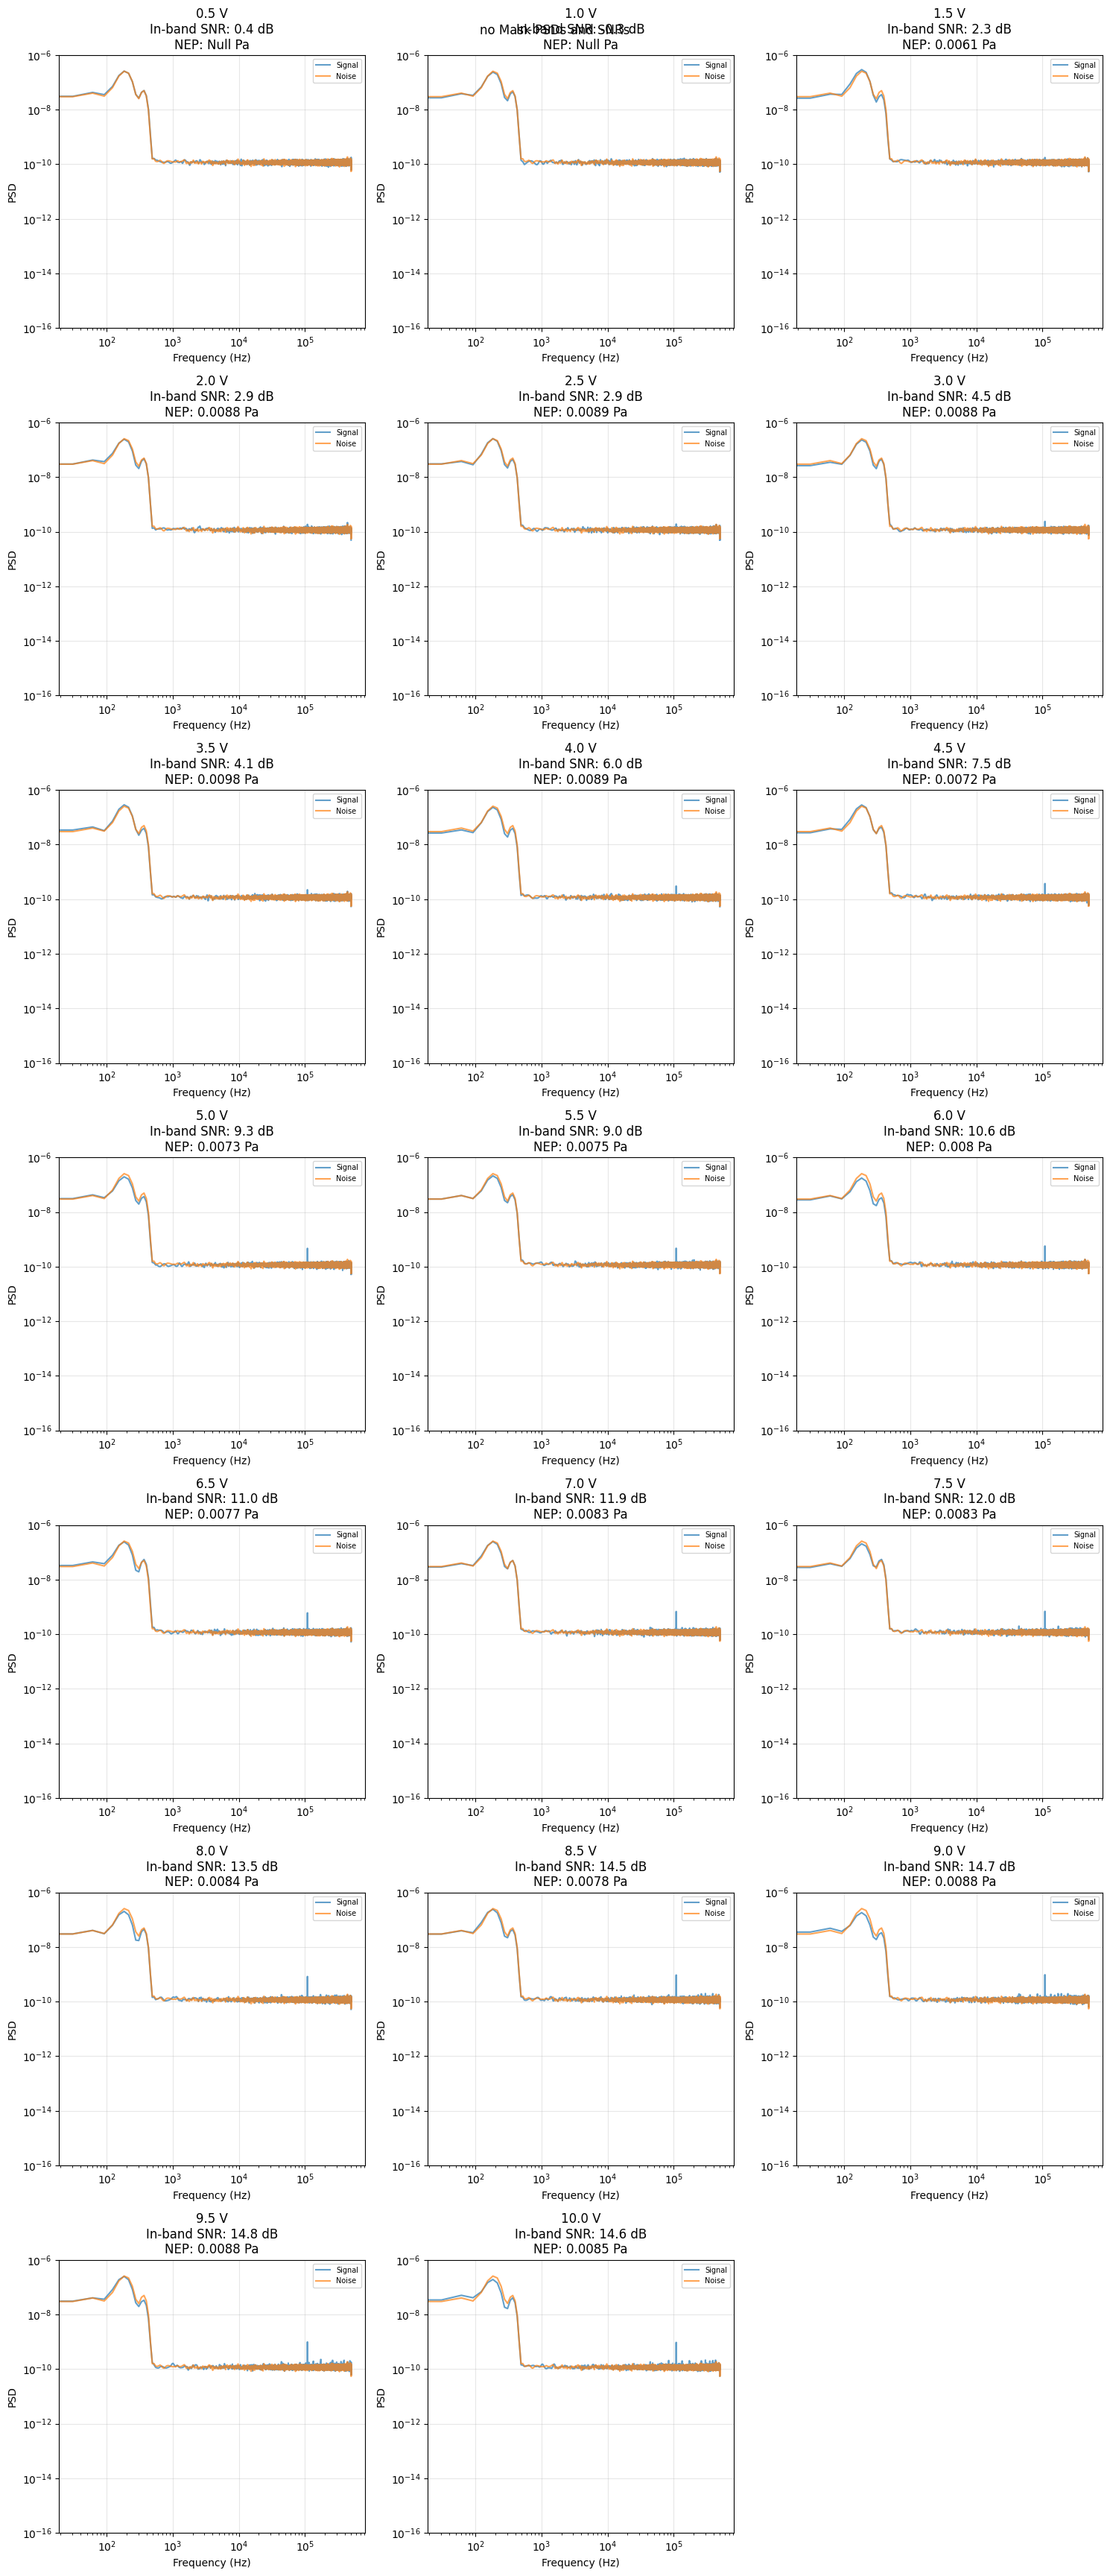

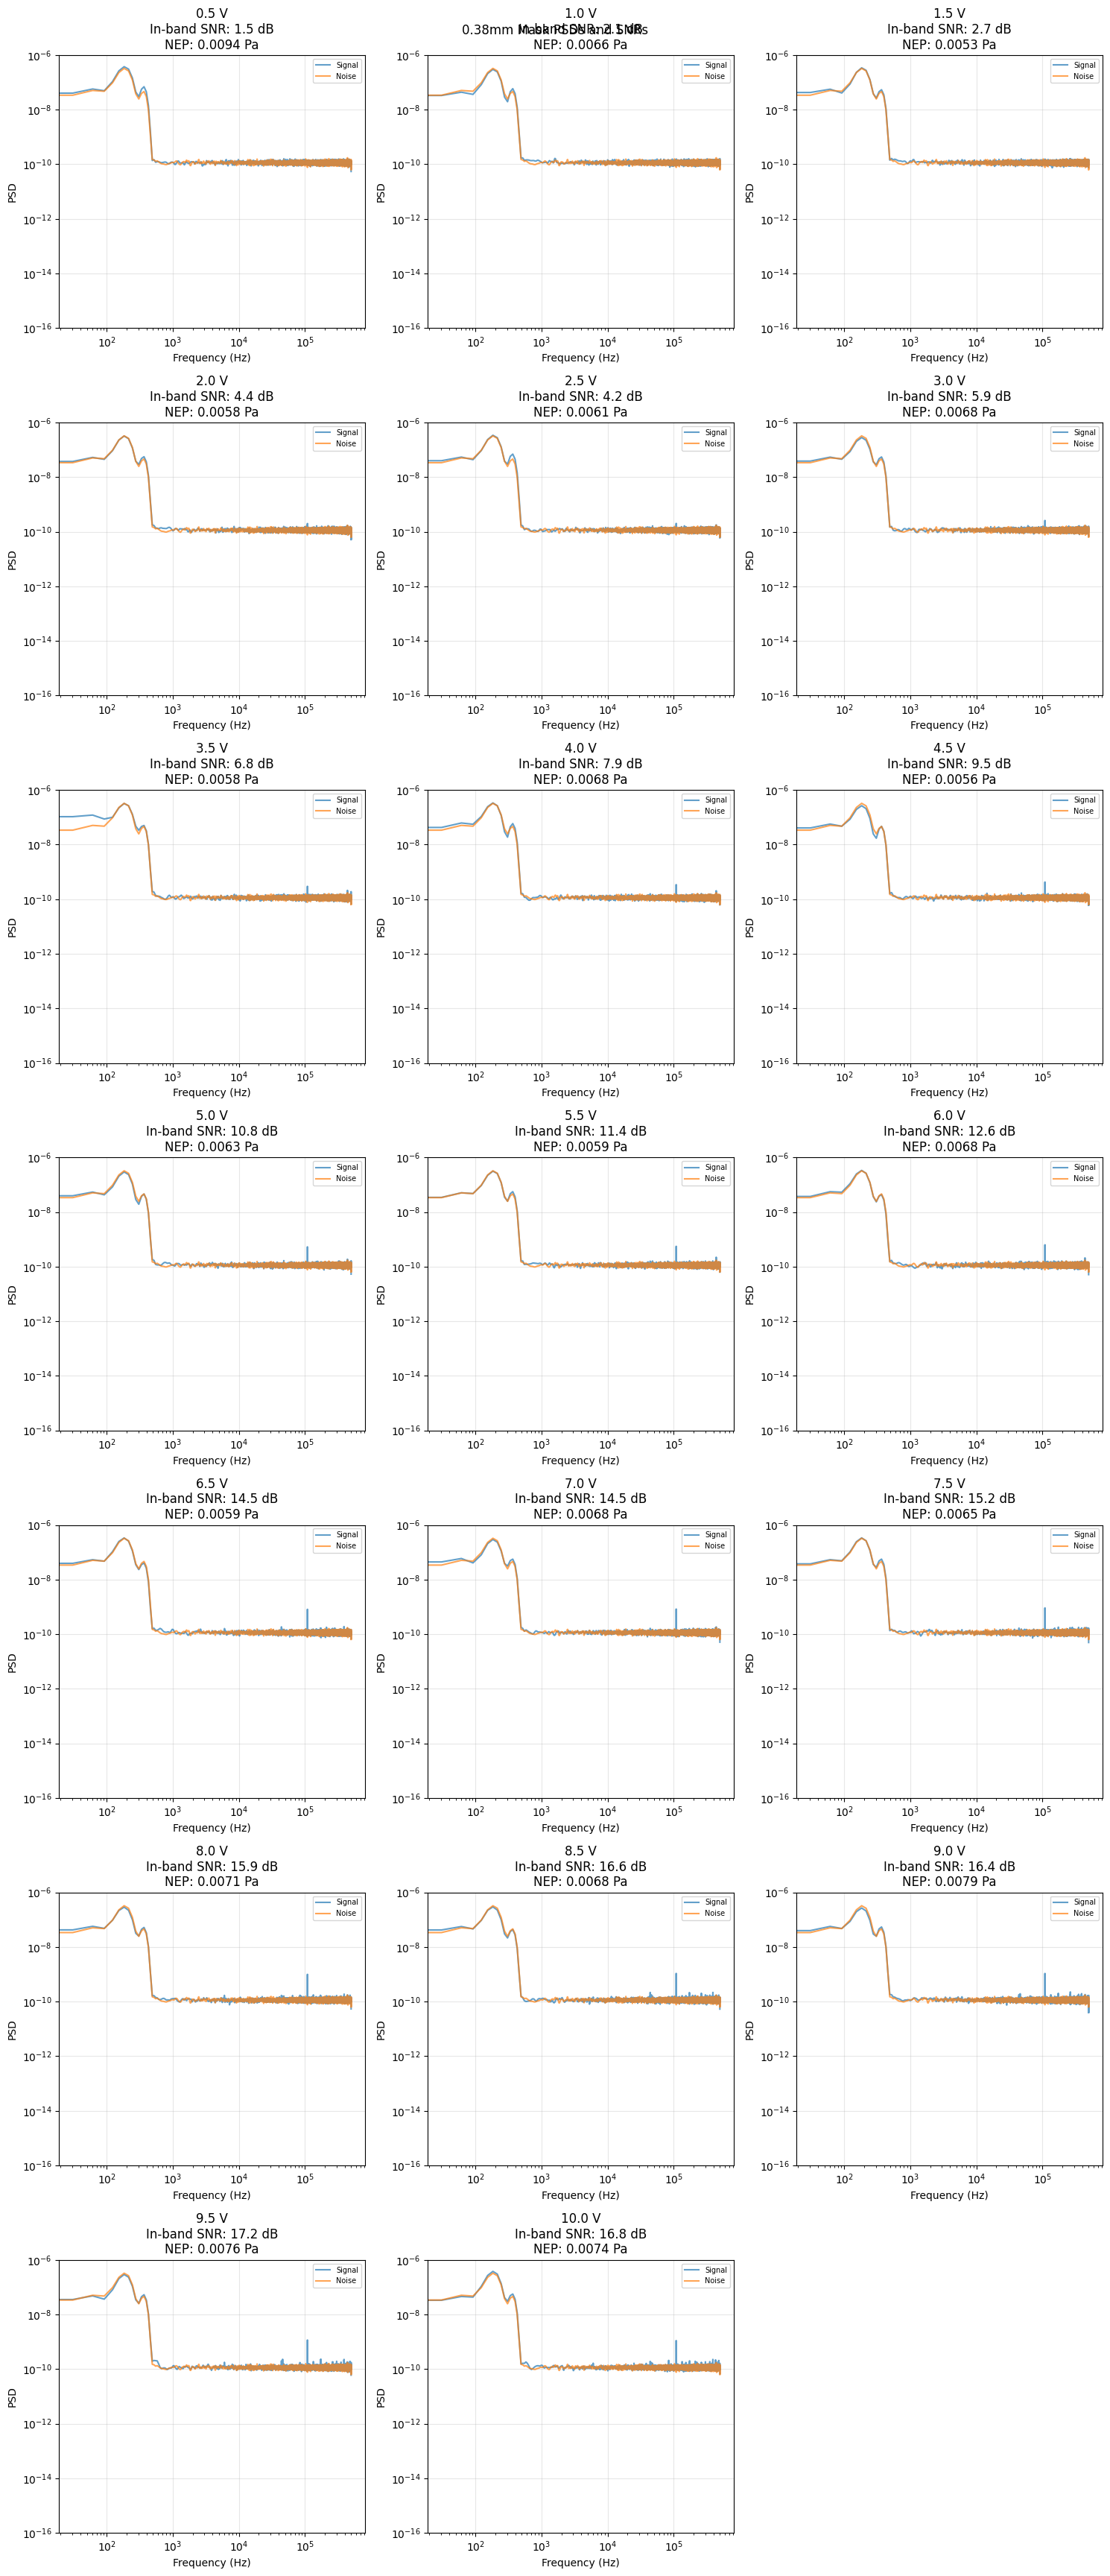

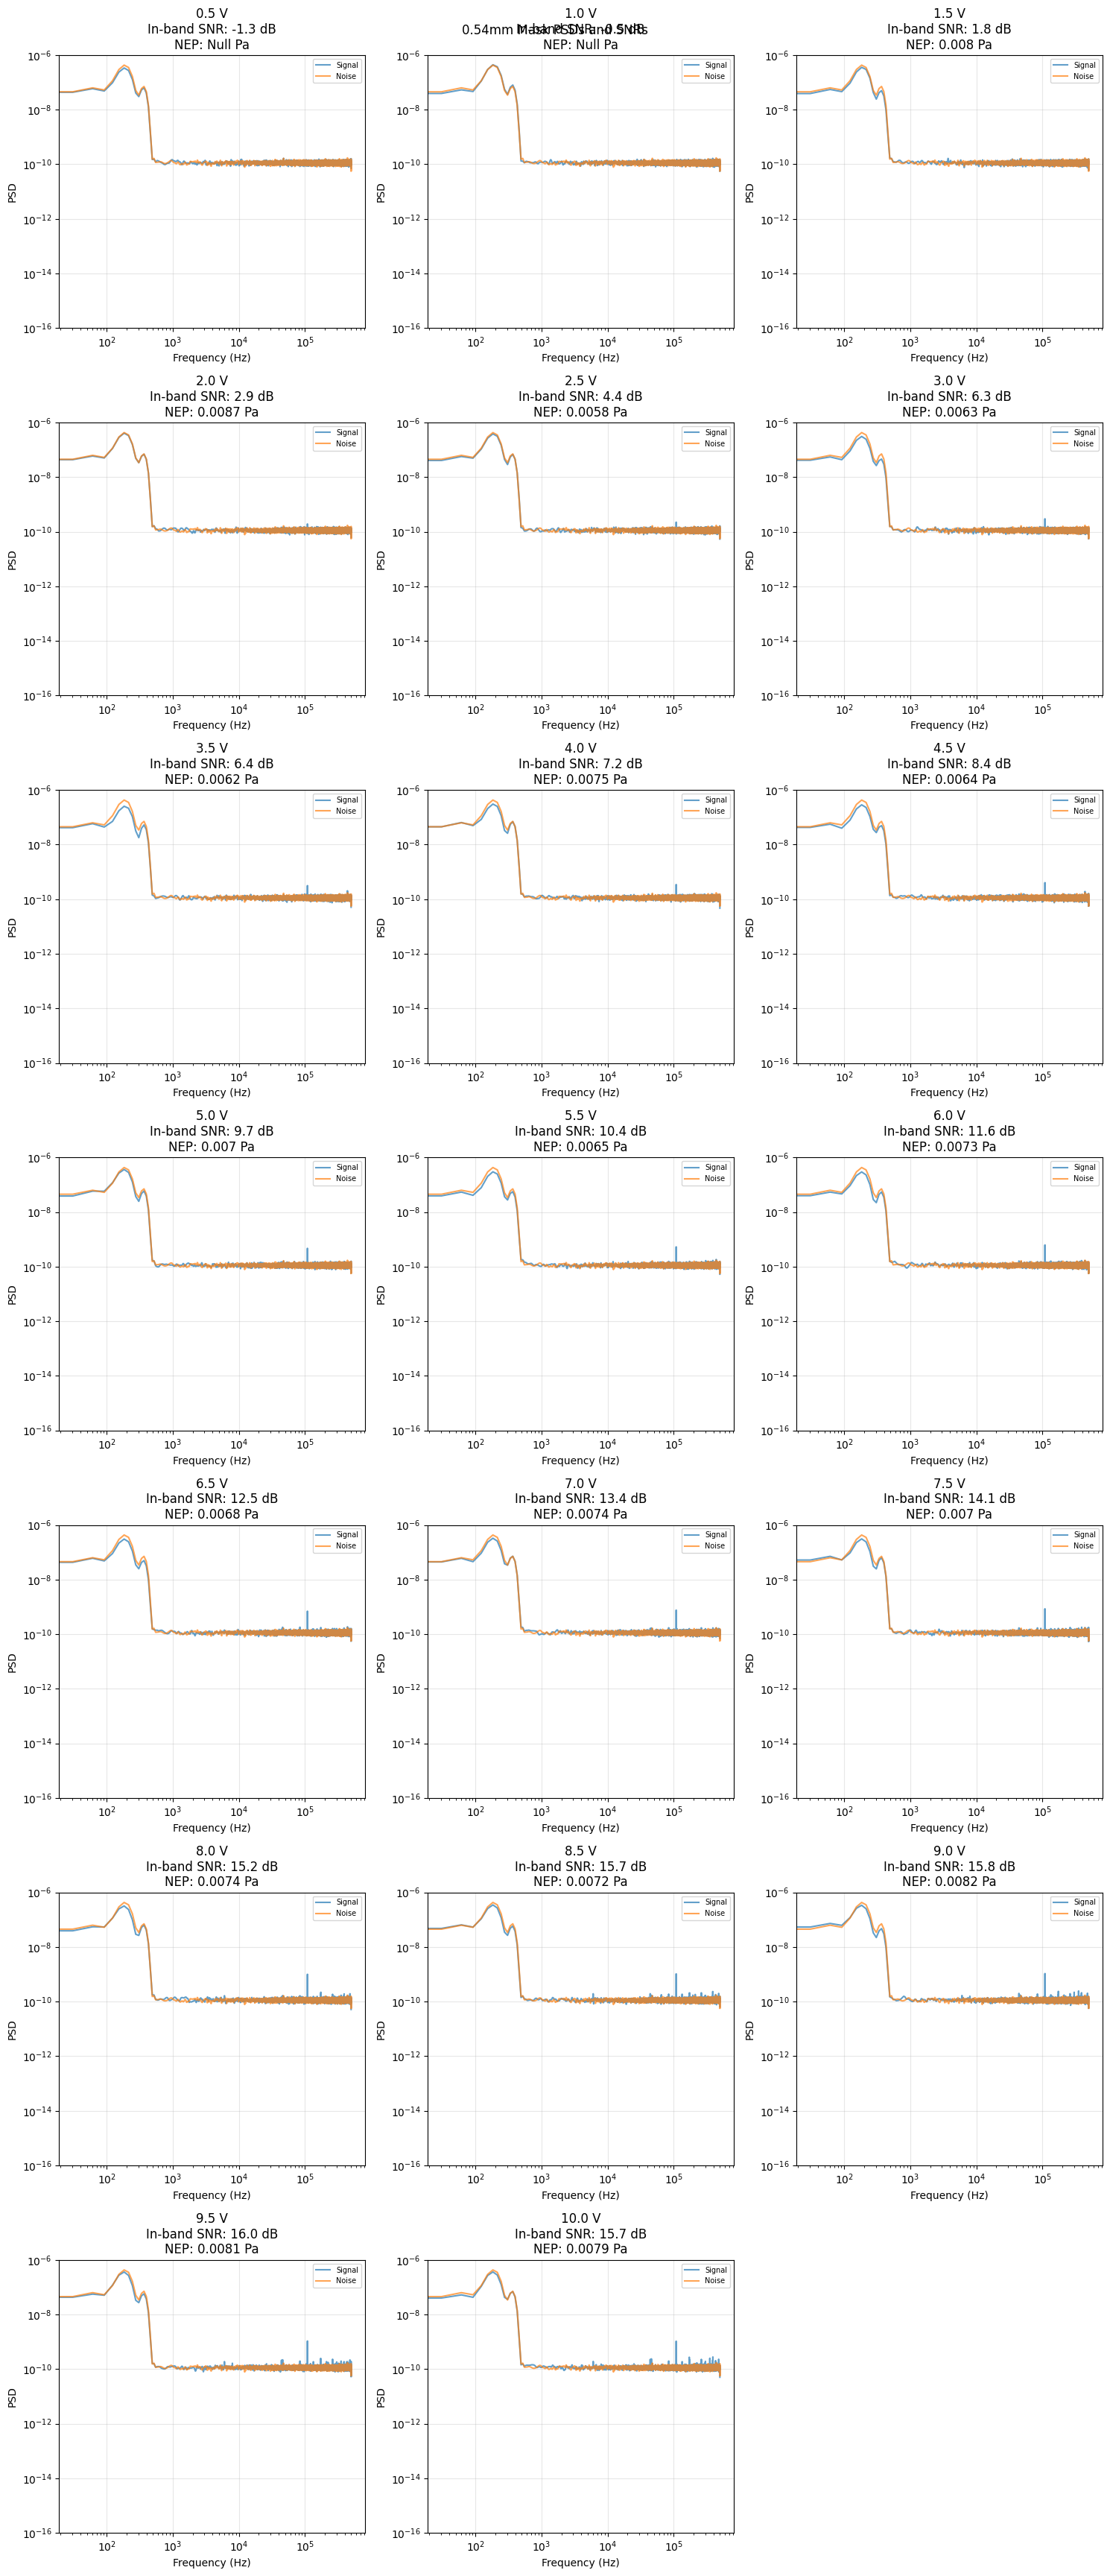

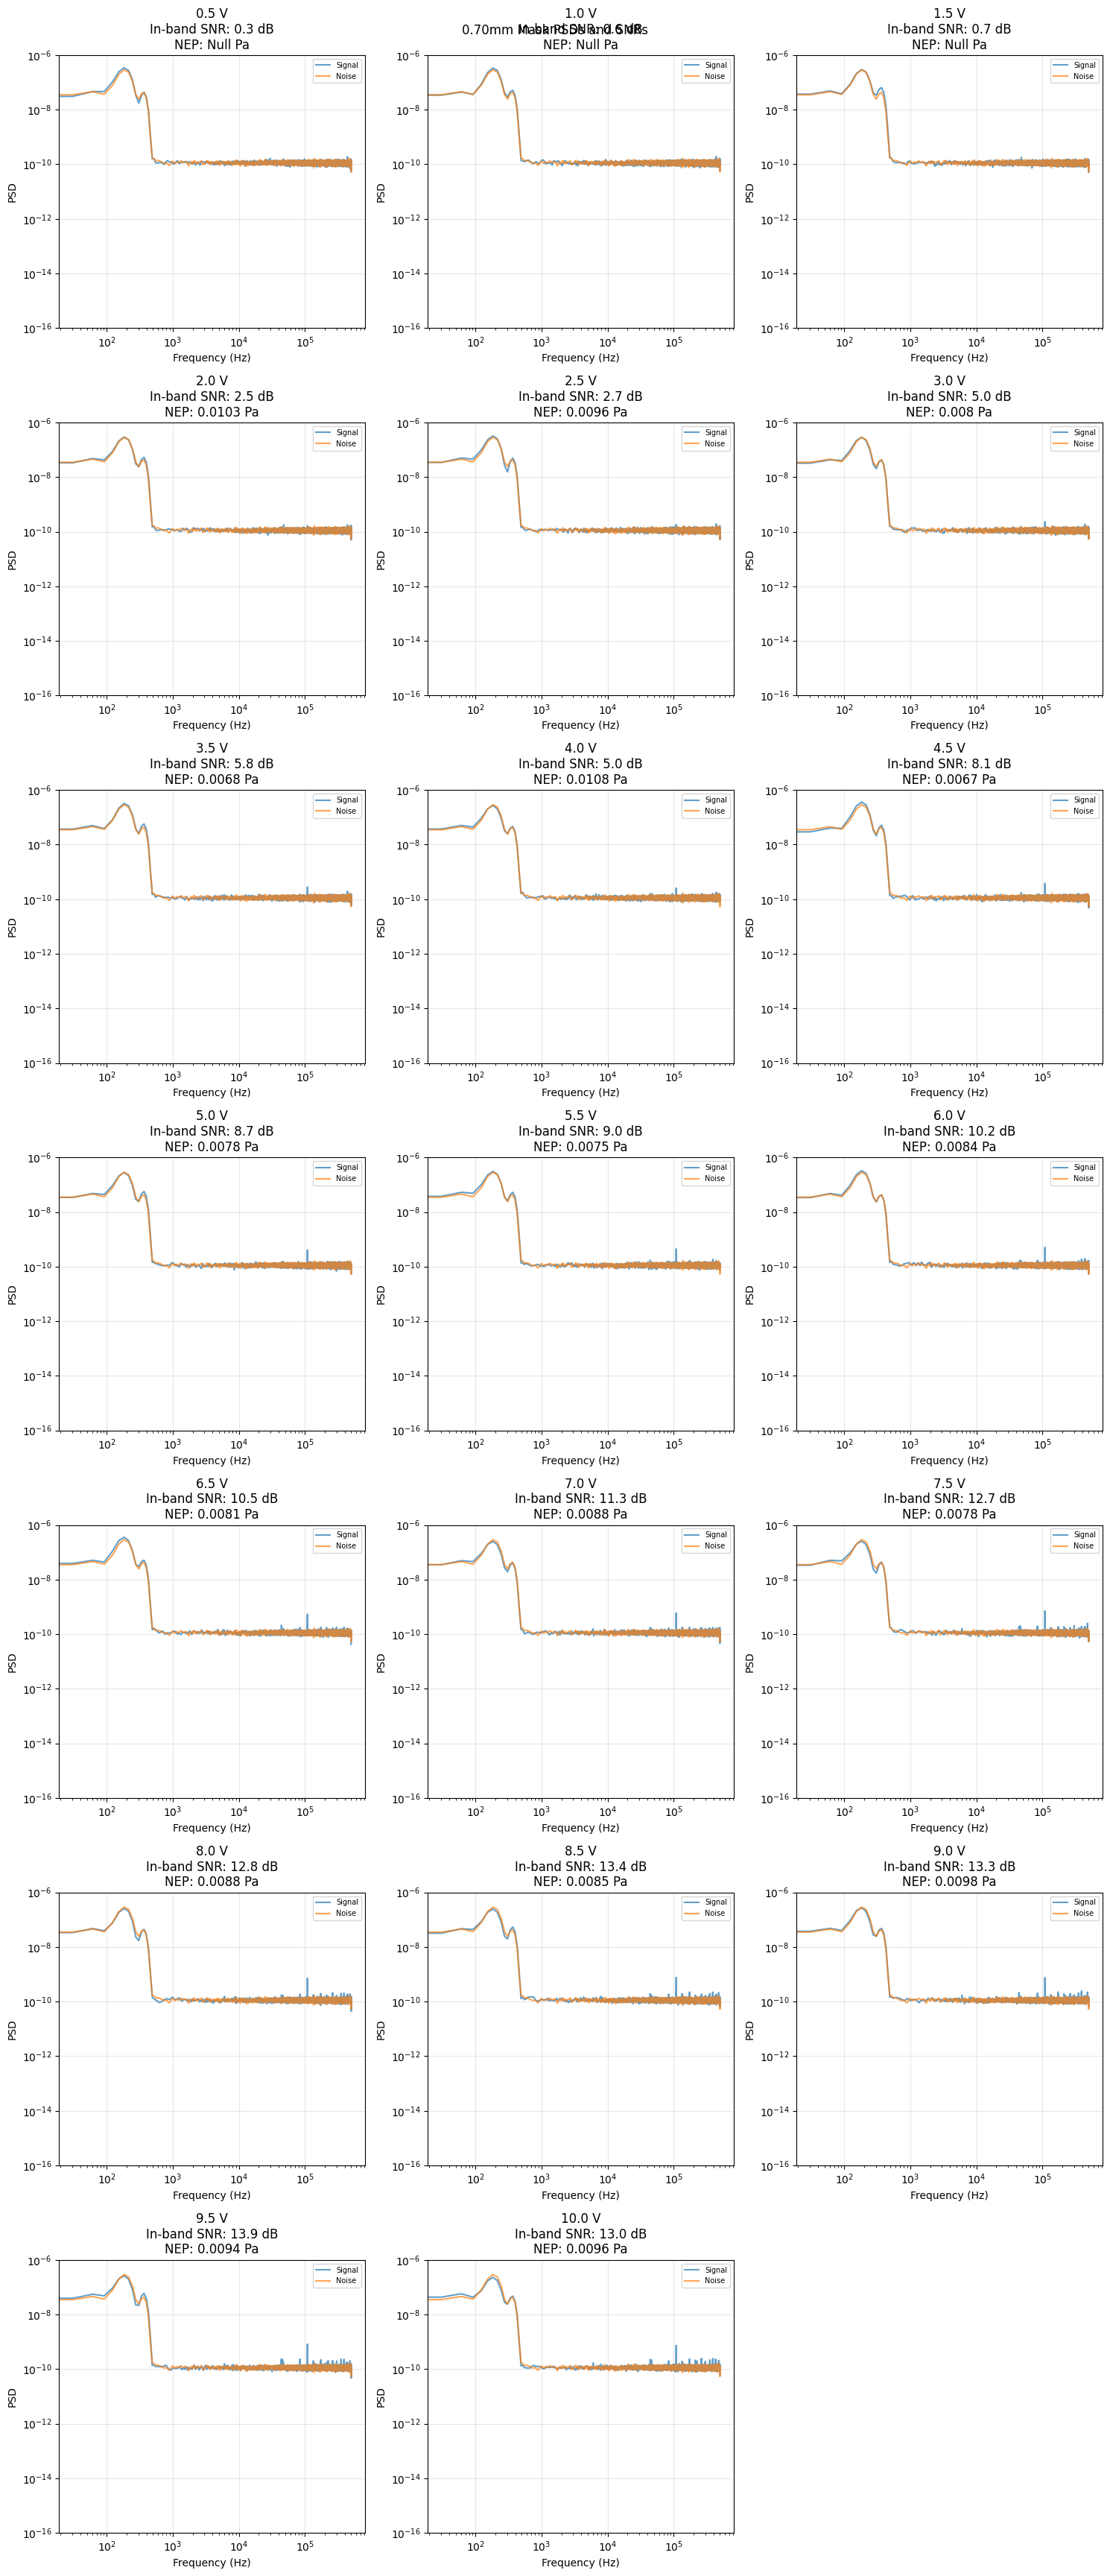

In [33]:
masks = ["no", "0.38mm", "0.54mm", "0.70mm"]
fig3, ax3 = plt.subplots(figsize=(6, 4))

for mask in masks:
    results = analysis_periodogram(base_path, mask_size=mask, test_type=normalized, band_half_width_hz=1e2, center_frequency_hz=109000)
    voltage_values = sorted(results.keys())
    snr_values = [results[voltage]["snr_inband"] for voltage in voltage_values]

    ax3.plot(voltage_values, snr_values, "o-", label=f"Mask:{mask}")

ax3.set_xlabel("Voltage (V)")
ax3.set_ylabel("In-band SNR (dB)")
ax3.set_title("SNR vs voltage")
ax3.grid(True, alpha=0.3)
ax3.legend()
fig3.tight_layout()
plt.show()

pk:slice(np.int64(7139), np.int64(7148), None)
[108934.15732052 108949.41634241 108964.67536431 108979.93438621
 108995.1934081  109010.45243    109025.7114519  109040.97047379
 109056.22949569]
SNR in 15 Hz: -3.2 dB (+3.7 / -nan dB)


C:\Users\sl57562\AppData\Local\Temp\ipykernel_28308\1083370839.py:90: RuntimeWarning: invalid value encountered in log10
  print(f"SNR in {df:.0f} Hz: {10 * np.log10(m):.1f} dB (+{10 * np.log10((m + e) / m):.1f} / -{10 * np.log10(m / (m - e)):.1f} dB)")


pk:slice(np.int64(7139), np.int64(7148), None)
[108934.15732052 108949.41634241 108964.67536431 108979.93438621
 108995.1934081  109010.45243    109025.7114519  109040.97047379
 109056.22949569]
SNR in 15 Hz: 21.4 dB (+0.8 / -1.0 dB)
pk:slice(np.int64(7139), np.int64(7148), None)
[108934.15732052 108949.41634241 108964.67536431 108979.93438621
 108995.1934081  109010.45243    109025.7114519  109040.97047379
 109056.22949569]
SNR in 15 Hz: 12.1 dB (+0.6 / -0.8 dB)
pk:slice(np.int64(7139), np.int64(7148), None)
[108934.15732052 108949.41634241 108964.67536431 108979.93438621
 108995.1934081  109010.45243    109025.7114519  109040.97047379
 109056.22949569]
SNR in 15 Hz: 15.3 dB (+0.5 / -0.6 dB)


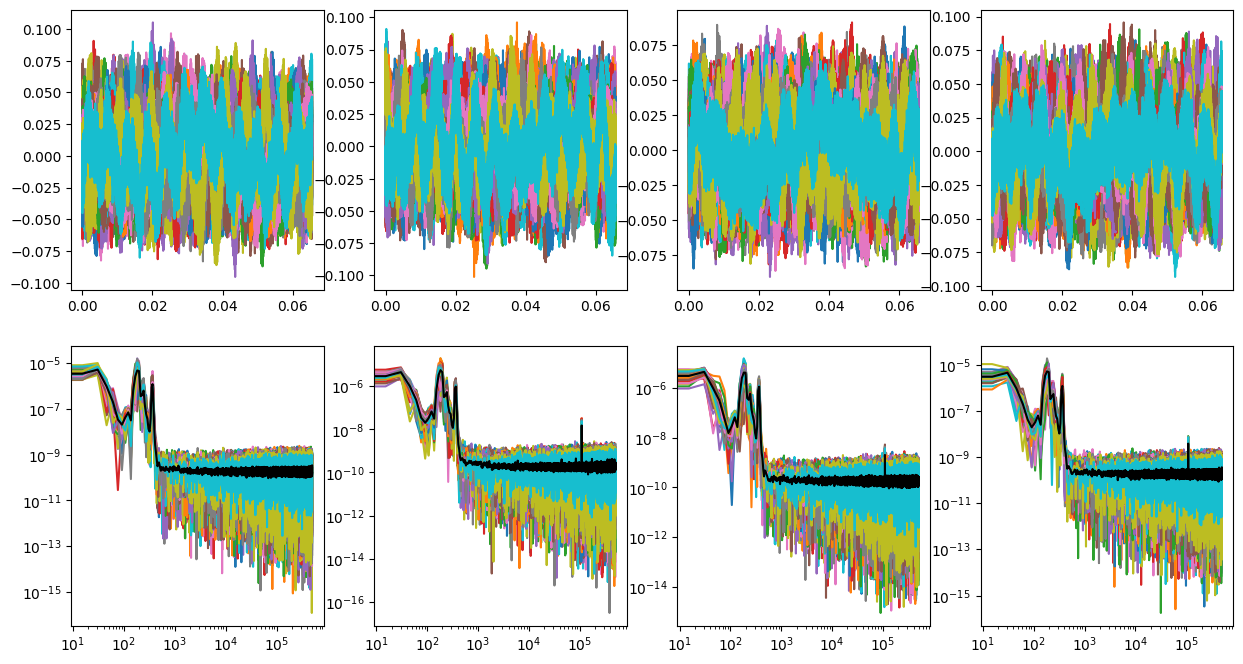

3764

In [32]:
#Zach's code

import numpy as np
import sys
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit as fit
from scipy.signal import periodogram
sys.path.append("../")
from analysis import System
import gc

def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx



from pathlib import Path

masks = ["no", "0.38mm", "0.54mm", "0.70mm"]
base_test_types = ["53mW_Pin", "1mW_Pout"]


def resolve_test_type(mask_size, test_type):
    if mask_size == "0.70mm" and test_type == "1mW_Pout":
        return "53mW_Pin"
    return test_type


base_path = Path(r"C:\Users\sl57562\The University of Texas at Austin\Acoustic + Calcium - Documents\Acoustic\paper data 3\20261019")
base_path = base_path.resolve()

file_list = []
for mask in masks:
    for test_type in base_test_types:
        resolved_test_type = resolve_test_type(mask, test_type)
        pattern = re.compile(rf"^{re.escape(mask)}Mask_{re.escape(resolved_test_type)}_(\d+(?:\.\d+)?)V$")
        for folder in sorted(base_path.iterdir()):
            if not folder.is_dir():
                continue
            if pattern.fullmatch(folder.name):
                file_list.extend(str(folder / f"iter_{i}.tdms") for i in range(10))

l = System("michelson", file_list, set_data=True, channel="X")



fig, ax = plt.subplots(2, 4, figsize = (15, 8))
freq = 109e3
for i in range(0, 80):
    l.set_data(ind = i)
    l.get_data()[i].apply("detrend", mode = "linear", inplace = True)
    ax[0][i // 20].plot(l.get_data()[i].collection[0].t, l.get_data()[i].collection[0].x)
    ax[0][i // 20].plot(l.get_data()[i].collection[1].t, l.get_data()[i].collection[1].x)
    f, p0 = periodogram(l.get_data()[i].collection[0].x, l.get_data()[i].r, window = "hann", detrend = "linear")
    _, p1 = periodogram(l.get_data()[i].collection[1].x, l.get_data()[i].r, window = "hann", detrend = "linear")
    ax[1][i // 20].loglog(f, p0)
    ax[1][i // 20].loglog(f, p1)
    if i % 20 == 0:
        P = []
    p = np.array((p0 + p1) / 2)
    ax[1][i // 20].loglog(f, p)
    P.append(p)
    if i % 20 == 19:
        P = np.array(P)
        Pm = np.mean(P, axis = 0)
        std = np.std(P, axis = 0) 
        ax[1][i // 20].loglog(f, Pm, c = "k")

        df = f[1] - f[0]
        ix = np.argmin(np.abs(f - freq))
        ix += np.argmax(Pm[ix - 3 : ix + 4]) - 3
        pk = slice(ix - 4, ix + 5)
        print(f"pk:{pk}")
        print(f[7139:7148])
        nb = (np.abs(f - f[ix]) > 20 * df) & (np.abs(f - f[ix]) < 100 * df)
        assert nb.sum() > 50, f"only {nb.sum()} noise bins"
        Sn = np.mean(Pm[nb])
        Psig = np.sum(Pm[pk] - Sn) * df
        if Psig <= 0:
            print("no detection: Psig <", 3 * np.std(Pm[nb]) * np.sqrt(9) * df, "V^2")
        else:
            snrs = [np.sum(Pi[pk] - np.mean(Pi[nb])) / np.mean(Pi[nb]) for Pi in P]
            m, e = np.mean(snrs), np.std(snrs, ddof = 1) / np.sqrt(len(snrs))
            print(f"SNR in {df:.0f} Hz: {10 * np.log10(m):.1f} dB (+{10 * np.log10((m + e) / m):.1f} / -{10 * np.log10(m / (m - e)):.1f} dB)")
    
plt.show()
plt.close()
gc.collect()